# 📓 Notebook 1: Teaching a computer to "understand" a PDF

ChatGPT has never read **your** college syllabus. So how can an AI answer questions about it?

The trick is called **RAG (Retrieval-Augmented Generation)**. It works like an **open-book exam** for the AI:
1. 📖 **Retrieve**: find the parts of the book that relate to the question
2. ✍️ **Generate**: let the AI write an answer using those parts

In this notebook we prepare the "book", and we print everything so you can see what happens at each step:

```
PDF ──► pages ──► chunks ──► embeddings (numbers) ──► picture! ──► search
```

## 1. Installation 📦
Run this once. After a fresh install, restart the kernel: **Kernel → Restart**.
(The `--extra-index-url` part downloads the small CPU-only version of PyTorch.)

In [ ]:
%pip install -q --extra-index-url https://download.pytorch.org/whl/cpu "torch==2.14.0" "sentence-transformers==6.1.0" "langchain-huggingface==1.2.2" "langchain-community==0.4.2" "langchain-text-splitters==1.1.2" "pypdf==6.19.0" "faiss-cpu==1.15.1" "numpy==2.4.6" "matplotlib==3.11.2" "scikit-learn==1.9.1" "tabulate==0.10.0"

## 2. Import the libraries 📚
| Library | What it does for us |
|---|---|
| `langchain_community` | ready-made tools: PDF loader, FAISS |
| `langchain_huggingface` | free embedding models from **Hugging Face** 🤗 |
| `langchain_text_splitters` | cuts long text into chunks |
| `numpy` | maths with lists of numbers |
| `matplotlib` + `scikit-learn` | draws pictures of our data |
| `tabulate` | prints neat tables |

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from tabulate import tabulate

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

print("✅ All libraries loaded!")

✅ All libraries loaded!


## 3. Document loading 📄
`PyPDFLoader` reads the PDF and gives us **one Document per page**.
Each Document has two parts: `page_content` (the text) and `metadata` (information *about* the text).

In [18]:
PDF_PATH = "../data/sample_syllabus.pdf"   # 👈 try your own PDF here!

pages = PyPDFLoader(PDF_PATH).load()

print("Number of pages:", len(pages))
print("Metadata of page 1:", pages[0].metadata)
print()
for page in pages:
    print(f"Page {page.metadata['page'] + 1}: {len(page.page_content)} characters")
print()
print("📖 First 300 characters of page 1:")
print(pages[0].page_content[:300])

Number of pages: 3
Metadata of page 1: {'producer': 'PyPDF', 'creator': 'PyPDF', 'creationdate': '', 'source': '../data/sample_syllabus.pdf', 'total_pages': 3, 'page': 0, 'page_label': '1'}

Page 1: 1867 characters
Page 2: 2056 characters
Page 3: 1572 characters

📖 First 300 characters of page 1:
SAMPLE COURSE HANDBOOK - CST 3XX: APPLIED MACHINE LEARNING (B.Tech CSE, Semester
6)
This handbook is an illustrative teaching sample prepared for the Retrieval-Augmented
Generation workshop. It describes the course structure, syllabus modules, examination
pattern, internal evaluation scheme, laborat


## 4. Chunking ✂️
A whole page is too big to search precisely, so we cut the text into small **chunks**.
* `chunk_size`: the maximum number of characters in one chunk
* `chunk_overlap`: how many characters are **repeated** between neighbouring chunks, so that a sentence cut in half is not lost

In [19]:
splitter = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=100)
chunks = splitter.split_documents(pages)

print(f"{len(pages)} pages became {len(chunks)} chunks")
print("Size of each chunk:", [len(c.page_content) for c in chunks])

3 pages became 31 chunks
Size of each chunk: [255, 270, 256, 269, 287, 225, 265, 270, 254, 252, 217, 247, 268, 258, 268, 238, 276, 274, 283, 271, 269, 139, 208, 281, 234, 273, 295, 293, 236, 262, 145]


👀 Let's **see** the overlap. The <span style="background:yellow;color:black">&nbsp;yellow&nbsp;</span> text appears at the end of one chunk **and** at the start of the next one.

In [20]:
YELLOW = "\033[43m\033[30m"   # special code that turns the text background yellow
RESET = "\033[0m"             # back to normal


def overlap_length(a, b):
    """How many characters at the END of a are repeated at the START of b?"""
    for size in range(min(len(a), len(b)), 0, -1):
        if a.endswith(b[:size]):
            return size
    return 0


# find the first pair of neighbouring chunks that share some text
for i in range(len(chunks) - 1):
    a, b = chunks[i].page_content, chunks[i + 1].page_content
    n = overlap_length(a, b)
    if n > 20:
        break

print(f"----- CHUNK {i} ({len(a)} characters) -----")
print(a[: len(a) - n] + YELLOW + a[len(a) - n :] + RESET)
print()
print(f"----- CHUNK {i + 1} ({len(b)} characters) -----")
print(YELLOW + b[:n] + RESET + b[n:])
print()
print(f"👉 {n} characters were repeated, so nothing is lost at the cut!")

----- CHUNK 0 (255 characters) -----
SAMPLE COURSE HANDBOOK - CST 3XX: APPLIED MACHINE LEARNING (B.Tech CSE, Semester
6)
This handbook is an illustrative teaching sample prepared for the Retrieval-Augmented
Generation workshop. It describes the course structure, syllabus modules, examination

----- CHUNK 1 (270 characters) -----
Generation workshop. It describes the course structure, syllabus modules, examination
pattern, internal evaluation scheme, laboratory guidelines and academic integrity rules for
a third-year Computer Science and Engineering elective. Students should use it to test how a

👉 85 characters were repeated, so nothing is lost at the cut!


## 5. Embedding model 🧠
Computers cannot compare *meanings*, but they can compare *numbers*.
An **embedding model** is a small neural network that turns any sentence into a list of numbers (a **vector**). Sentences with **similar meaning** get **similar numbers**.

We use `BAAI/bge-small-en-v1.5` (made by the Beijing Academy of Artificial Intelligence) from **Hugging Face** 🤗 (<https://huggingface.co>), the "GitHub of AI models", where thousands of models are shared for free. It is small but very good at **search**.
It runs on your laptop without an API key. The first run downloads it (about 130 MB).

In [21]:
embedding_model = HuggingFaceEmbeddings(model_name="BAAI/bge-small-en-v1.5")
print("✅ Embedding model loaded:", embedding_model.model_name)

I0000 00:00:1790516940.204565   29213 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790516940.588316   29213 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790516941.695035   29213 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


README.md: 0.00B [00:00, ?B/s]

✅ Embedding model loaded: sentence-transformers/all-MiniLM-L6-v2


## 6. Embedding 🔢
Let's turn a sentence into numbers.

In [22]:
vector = np.array(embedding_model.embed_query("Hello students of KTU!"))

print("Shape of the vector:", vector.shape)
print("First 5 numbers   :", vector[:5])
print(f"\n🤯 One short sentence became {len(vector)} numbers!")

Shape of the vector: (384,)
First 5 numbers   : [-0.02284184  0.0383161   0.03138909  0.01644656 -0.07356308]

🤯 One short sentence became 384 numbers!


### Which sentences are "close" in meaning? 📐
We compare two vectors with **cosine similarity**: **1** means the same meaning and **0** means unrelated.

🤔 **Guess first:** is sentence A closer to B or to C?

In [23]:
A = "Syllabus guidelines on exam patterns"
B = "Evaluation metrics and internal marks"
C = "The solar system consists of planets"

vec_a, vec_b, vec_c = [np.array(v) for v in embedding_model.embed_documents([A, B, C])]


def cosine_similarity(x, y):
    return np.dot(x, y) / (np.linalg.norm(x) * np.linalg.norm(y))


print(tabulate(
    [["A vs B", B, round(cosine_similarity(vec_a, vec_b), 3)],
     ["A vs C", C, round(cosine_similarity(vec_a, vec_c), 3)]],
    headers=["Pair", f"Compared with A = '{A}'", "Similarity"],
    tablefmt="rounded_grid",
))

╭────────┬────────────────────────────────────────────────────────────┬──────────────╮
│ Pair   │ Compared with A = 'Syllabus guidelines on exam patterns'   │   Similarity │
├────────┼────────────────────────────────────────────────────────────┼──────────────┤
│ A vs B │ Evaluation metrics and internal marks                      │        0.29  │
├────────┼────────────────────────────────────────────────────────────┼──────────────┤
│ A vs C │ The solar system consists of planets                       │        0.053 │
╰────────┴────────────────────────────────────────────────────────────┴──────────────╯


Now we embed **every chunk** of the PDF:

In [24]:
chunk_texts = [c.page_content for c in chunks]
chunk_vectors = np.array(embedding_model.embed_documents(chunk_texts))

print("All chunk vectors together:", chunk_vectors.shape, "→ (number of chunks, numbers per chunk)")

All chunk vectors together: (31, 384) → (number of chunks, numbers per chunk)


## 7. Visualization 🎨
### (a) The "fingerprint" of a sentence
The 384 numbers are drawn as coloured squares (red = positive, blue = negative). Different meaning gives a different pattern.

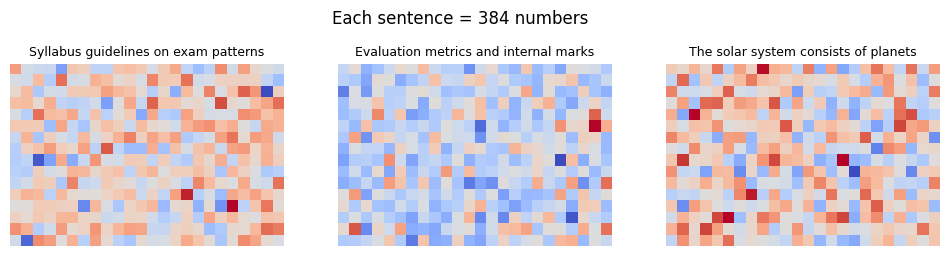

In [25]:
sentences = [A, B, C]
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, text, vec in zip(axes, sentences, [vec_a, vec_b, vec_c]):
    ax.imshow(vec.reshape(16, 24), cmap="coolwarm")   # 384 numbers = 16 rows x 24 columns
    ax.set_title(text, fontsize=9)
    ax.axis("off")
plt.suptitle("Each sentence = 384 numbers")
plt.show()

### (b) A map of meaning 🗺️
We cannot draw 384 dimensions, so **PCA** squeezes each vector down to just **2 numbers (x, y)** that we can plot.
Each dot is a chunk of the PDF. Chunks about similar topics end up **near each other**. The ⭐ is our question.

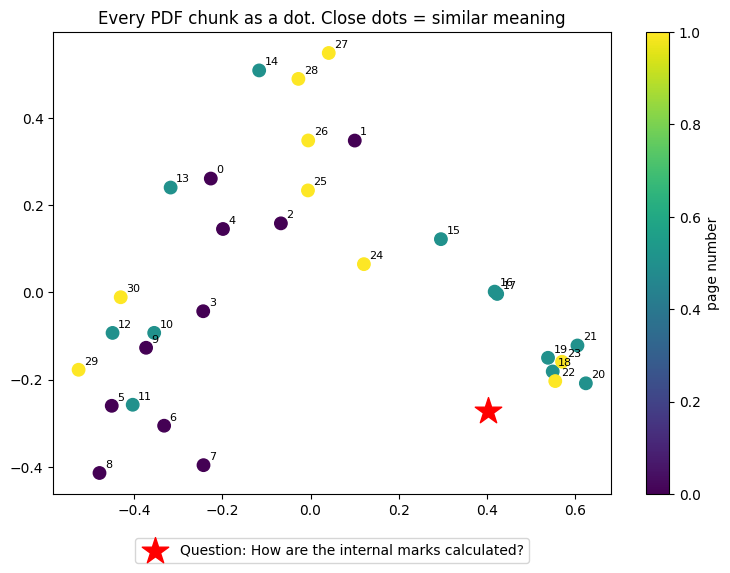

Chunks closest to the ⭐ on the map: [22, 18, 19]
👉 Read one of them: 9. Grading and Pass Criteria
The total mark for the course is 150 (50 CIE + 100 ESE). A student passes the course by
securing at least 40 percent in the End Semester Examination and at least 45 percen ...


In [26]:
question = "How are the internal marks calculated?"
question_vector = np.array(embedding_model.embed_query(question))

pca = PCA(n_components=2)
points = pca.fit_transform(np.vstack([chunk_vectors, question_vector]))   # 384 numbers -> 2 numbers
chunk_points, question_point = points[:-1], points[-1]

plt.figure(figsize=(9, 6))
page_numbers = [c.metadata["page"] + 1 for c in chunks]
plt.scatter(chunk_points[:, 0], chunk_points[:, 1], c=page_numbers, cmap="viridis", s=80)
for i, (x, y) in enumerate(chunk_points):
    plt.annotate(str(i), (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.scatter(*question_point, marker="*", s=400, color="red", label=f"Question: {question}")
plt.colorbar(label="page number")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.title("Every PDF chunk as a dot. Close dots = similar meaning")
plt.show()

nearest = np.argsort(np.linalg.norm(chunk_points - question_point, axis=1))[:3]
print("Chunks closest to the ⭐ on the map:", list(nearest))
print("👉 Read one of them:", chunk_texts[nearest[0]][:200], "...")

## 8. Store everything in FAISS and search 🔍
**FAISS** (made by Meta) is a *vector database*: it stores all the vectors and quickly finds the ones **closest** to a question.
It returns a **distance** for each result: **lower = more similar**.

In [30]:
vector_db = FAISS.from_documents(chunks, embedding_model)
print(f"FAISS is storing {vector_db.index.ntotal} vectors, each {vector_db.index.d} numbers long\n")

question = "What is the exam pattern for the end semester exam?"
for doc, distance in vector_db.similarity_search_with_score(question, k=3):
    print(f"📏 distance = {distance:.3f}   (page {doc.metadata['page'] + 1})")
    print(doc.page_content)
    print("-" * 80)

FAISS is storing 31 vectors, each 384 numbers long

📏 distance = 0.585   (page 2)
The End Semester Examination is conducted for 100 marks with a duration of 3 hours. Part A
contains 10 short-answer questions, two from each module, each carrying 3 marks, for a total
of 30 marks. All questions in Part A are compulsory. Part B contains two questions from each
--------------------------------------------------------------------------------
📏 distance = 0.809   (page 2)
query rewriting and self-correction. Hallucination and evaluation of RAG systems. (9 hours)
7. Examination Pattern - End Semester Examination (ESE)
The End Semester Examination is conducted for 100 marks with a duration of 3 hours. Part A
--------------------------------------------------------------------------------
📏 distance = 0.961   (page 2)
of 30 marks. All questions in Part A are compulsory. Part B contains two questions from each
module, of which the student must answer one full question per module. Each Part B ques

🧪 **Experiment:** what happens to the distance when the PDF does **not** talk about the topic?

In [31]:
for q in ["How are internal marks calculated?", "Who won the football world cup?"]:
    doc, distance = vector_db.similarity_search_with_score(q, k=1)[0]
    print(f"{q:<40} → closest distance = {distance:.3f}")

How are internal marks calculated?       → closest distance = 0.756
Who won the football world cup?          → closest distance = 1.759


## 🎉 What you just built
**PDF → chunks → vectors → FAISS → search.** This is the "open book" part of RAG.

In **Notebook 2** we add an **LLM** that reads these chunks and answers like a chatbot, and give it **memory**.

**Try it yourself:**
* Change `chunk_size` to 100 or 1000. What happens to the number of chunks?
* Add a sentence D in step 6. Can you get a similarity above 0.8 with A?
* Ask a different question in step 7(b). Where does the ⭐ move?